In [1810]:
# population studies using multi-class classification
import numpy as np
import pandas as pd
from matplotlib import pyplot
from scipy.stats import binom
print(np.__version__)
from scipy.optimize import minimize

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve
from sklearn.calibration import calibration_curve

import os
import sys
if '../../lib/' not in sys.path:
    sys.path.append('../../lib/')
import dio3
import multi_fgl_utils as util
import plot_util as putil

1.21.5


In [1811]:
if 1:
    import importlib
    importlib.reload(util);


In [1812]:
def gauss_pdf(mu, sigma):
    pf = 1 / np.sqrt(2. * np.pi * sigma**2)
    def f(x):
        return pf * np.exp(-(x - mu)**2 / (2. * sigma**2))
    return f

In [1813]:
purpose = 'SGU-paper' # 'DFG', 'multi-paper'
add_4lac = False
folder = '../../data_out/'
tree_alg = 'RF' # 'stat', 'GMM', 'RF', '4class', tree_alg == '2class_gal_egal'
mode = 'no_bcu_spp' # 'all_assoc', 'no_bcu_spp'
if mode == 'all_assoc':
    mode_str = ''
else:
    mode_str = '_%s' % mode

class_name = 'CLASS1'
descr_str = ''
if tree_alg == 'GMM':
    nmin = 100
    tree_cat_fn = folder + 'tree_cat_nmin%i%s.yaml' % (nmin, mode_str)
    descr_str += '_nmin%i_%s%s' % (nmin, tree_alg, mode_str)
elif tree_alg == 'RF':
    if mode == 'no_bcu_spp':
        nmin = 60
    else:
        nmin = 100
    tree_cat_fn = folder + 'tree_cat_nmin%i_RF%s.yaml' % (nmin, mode_str)
    descr_str += '_nmin%i_%s%s' % (nmin, tree_alg, mode_str)
        
elif tree_alg == '2class_gal_egal':
    tree_cat_fn = folder + 'tree_cat_2class_gal_egal.yaml'
    title_dict = {'00': 'Extragalactic', '01': 'Galactic'}
    plots_folder = '../../plots/dfg/pop_studies/'
    

tree_cat_dict = dio3.loaddict(tree_cat_fn)
nclasses = len(tree_cat_dict)
max_tree_cat_dict = util.tree2max_tree(tree_cat_dict)
dec_tree_cat_dict = util.max_tree2dec_tree(max_tree_cat_dict)
nodes = [str(key) for key in dec_tree_cat_dict.keys()]

folder_in = '../../results/4FGL-DR3_probabilistic_classification/'
alg_descr = '_%s' % tree_alg
if tree_alg == 'GMM' or tree_alg == 'RF':
    alg_descr += '_nmin%s' % (nmin)
elif tree_alg == '2class':
    alg_descr += '_gal_egal'
alg_descr += mode_str
feature_mode = 'no coord features'
if feature_mode == 'no coord features':
    alg_descr += '_no_coord_features'


if tree_alg == 'GMM' or tree_alg == 'RF':
    fn = folder_in + '4FGL-DR3_%iclass%s_prob_cat.csv' % (nclasses, alg_descr)
    #fn = folder_in + '4FGL-DR3_%iclass_pcat.csv' % nclasses
    #algs = ['RF', 'NN']
    algs = ['RF',]
elif tree_alg == '2class_gal_egal':
    fn = folder_in + '4FGL-DR3_%s_pcat.csv' % tree_alg
    #algs = ['RF', 'NN']
    algs = ['RF',]

print(fn)
cat_df = pd.read_csv(fn, index_col=0)
all_assoc = []
for cls in tree_cat_dict.values():
    all_assoc.extend(cls)

fig_size =  [8, 6]
fig_1d_dict = {'fig_size':fig_size, 'axes.titlesize': 22}


../../results/4FGL-DR3_probabilistic_classification/4FGL-DR3_5class_RF_nmin60_no_bcu_spp_no_coord_features_prob_cat.csv


In [1814]:
descr_str, alg_descr

('_nmin60_RF_no_bcu_spp', '_RF_nmin60_no_bcu_spp_no_coord_features')

In [1815]:
print(util.cl_list2str(all_assoc))

bll, sbg, rdg, msp, snr, pwn, gc, gal, ssrq, sey, css, agn, fsrq, nlsy1, psr, glc, sfr, bin, hmb, nov, lmb


In [1816]:
print(util.cl_list2str(features))

sin(GLAT), cos(GLON), sin(GLON), log10(Energy_Flux100), log10(Unc_Energy_Flux100), log10(Signif_Avg), LP_index1000MeV, LP_beta, LP_SigCurv, log10(Variability_Index)


In [1817]:
if add_4lac:
    from astropy.io import fits
    fn = '../data_in/table-4LAC-DR2-h.fits'
    hdu = fits.open(fn)
    lach = hdu[1].data
    fn = '../data_in/table-4LAC-DR2-l.fits'
    hdu = fits.open(fn)
    lacl = hdu[1].data
    #cnames = [cat_hdu[1].header[key] for key in cat_hdu[1].header.keys() if key.startswith('TTYPE')]
    #cnames = [clm.name for clm in lach.columns]
    lac_lats = list(lach['GLAT']) + list(lacl['GLAT'])
    sin_lac_lats = np.sin(np.deg2rad(lac_lats))
    print(len(lach), len(lacl))

In [1854]:
folder = '../../data_out/'
Eind = 1000
xdf_fn = folder + 'xdf_fgl_Eind%iMeV.csv' % Eind
#xdf_fn = folder + 'xdf_fgl.csv'
xdf = pd.read_csv(xdf_fn, index_col=0)
features = [name for name in xdf.columns if name != 'CLASS1']
ns = len(xdf)
assoc_mask = util.get_cl_mask(all_assoc, xdf, cname=class_name)
unas_type = 'bcu' # 'unas', 'bcu', 'spp', 'all_not_assoc'
descr_str += '_%s' % unas_type
if unas_type == 'all_not_assoc':
    unas_mask = ~assoc_mask
    unas_label = 'unas unk bcu spp'
else:
    unas_mask = util.get_cl_mask([unas_type], xdf, cname=class_name)
    unas_label = unas_type

#unas_mask = (cat_df['CLASS1'] == 'unas') | (cat_df['CLASS1'] == 'unk')

if tree_alg == 'GMM' or tree_alg == 'RF':
    pgroup1 = nodes[:3]
    pgroup2 = nodes[3:]
elif tree_alg == '2class_gal_egal':
    pgroup1 = nodes[:1]
    pgroup2 = nodes[1:]
    

In [1855]:
putil.setup_figure_pars()
size = 5
ncols = 1
nrows1 = len(pgroup1)
nrows2 = len(pgroup2)
fig_size_1plot = pyplot.rcParams['figure.figsize']
if nrows1 == 1 and nrows2 == 1:
    fig_size1 =  pyplot.rcParams['figure.figsize']
    fig_size2 =  pyplot.rcParams['figure.figsize']
else:
    if purpose != 'DFG':
        pyplot.rcParams['axes.titlesize'] =  18
        pyplot.rcParams['figure.subplot.bottom'] =  0.05
        pyplot.rcParams['figure.subplot.top'] =  0.97

    fig_width = size * ncols + size/2  # width in inches
    
    fig_height1 = size * nrows1 + size/2   # height in inches
    
    fig_height2 = size * nrows2 + size/2   # height in inches
    fig_size1 =  [fig_width, fig_height1]
    fig_size2 =  [fig_width, fig_height2]


colors = pyplot.rcParams['axes.prop_cycle'].by_key()['color']
lss = {'RF':'--', 'NN':'-.'}
plot_all_assoc = False
save_plots = 0
save_png = 0
copy2tex = 0

if purpose == 'multi-paper':
    plots_folder = '../../plots/mclass/pop_study/'
    paper_folder = '/Users/Dmitry/Work/Fermi/fermi_multiclass_papers/multi_class_paper1\
/multi_class_paper1_git/'
    plots_folder_paper = paper_folder + 'plots/pop_study/'
elif purpose == 'DFG':
    plots_folder = '../../plots/dfg/pop_study/'
    plots_folder_paper = '/Users/Dmitry/official/grants/DFG_2022_Fermi-multi/DFG_multiclass22_git/\
DFG_multiclass22/plots/pop_study/'
elif purpose == 'SGU-paper':
    plots_folder = '../../plots/pop_study/%s/' % (alg_descr[1:])
    plots_folder_extra = plots_folder + 'extra/'
    paper_folder = '/Users/Dmitry/Work/Fermi/fermi_multiclass_papers/SGU_paper\
/SGU_paper_git/'
    plots_folder_paper = paper_folder + 'plots/pop_study/'
    
if not os.path.isdir(plots_folder):
    os.makedirs(plots_folder)

if not os.path.isdir(plots_folder_extra):
    os.makedirs(plots_folder_extra)

if not os.path.isdir(plots_folder_paper):
    os.makedirs(plots_folder_paper)


In [1856]:
cls_masks = {}
for node in nodes:
    cls_masks[node] = util.get_cl_mask(dec_tree_cat_dict[int(node)], xdf, cname='CLASS1')

In [1857]:
# feature mask
fmask0 = np.ones(len(xdf), dtype=bool)
bmask = 10
fmask_hlat = np.abs(xdf['sin(GLAT)']) > np.sin(np.deg2rad(bmask)) # select high latitudes
fmask_llat = np.abs(xdf['sin(GLAT)']) < np.sin(np.deg2rad(bmask)) # select low latitudes
lmask = 20
fmask_lon_out = xdf['cos(GLON)'] < np.cos(np.deg2rad(lmask)) # select outer galaxy
fmask_lon_in = xdf['cos(GLON)'] > np.cos(np.deg2rad(lmask)) # select inner galaxy

In [1858]:
# lat plot
plot_sin_glat = True
sin_glat = xdf['sin(GLAT)']
sin_glat_bins = np.linspace(-1, 1, 21)
if plot_sin_glat:
    binc = (sin_glat_bins[1:] + sin_glat_bins[:-1]) / 2.
    xlabel = 'sin(GLAT)'
else:
    glat_bins = np.rad2deg(np.arcsin(sin_glat_bins))
    binc = (glat_bins[1:] + glat_bins[:-1]) / 2.
    xlabel = 'GLAT'
bins = sin_glat_bins
values = sin_glat


In [1859]:
fmask = fmask_lon_out
#fmask = fmask_llat
hist_all_assoc = np.histogram(values[assoc_mask & fmask], bins=bins)[0]
hist_all_unassoc = np.histogram(values[unas_mask & fmask], bins=bins)[0]


if add_4lac:
    lac_sin_lats_hist = np.histogram(sin_lac_lats, bins=bins)[0]
    
assoc_count_hists = {}
assoc_prob_hists = {}
unas_hists = {}
for node in nodes:
    assoc_count_hists[node] = np.histogram(values[cls_masks[node] & fmask], bins=bins)[0]
    for alg in algs:
        key = '%s_%s' % (node, alg)
        assoc_prob_hists[key] = np.histogram(values[assoc_mask & fmask], bins=bins, 
                                      weights=cat_df[key][assoc_mask & fmask])[0]
        unas_hists[key] = np.histogram(values[unas_mask & fmask], bins=bins, 
                                      weights=cat_df[key][unas_mask & fmask])[0]



In [1860]:
fig_size1, fig_size2

([7.5, 17.5], [7.5, 12.5])

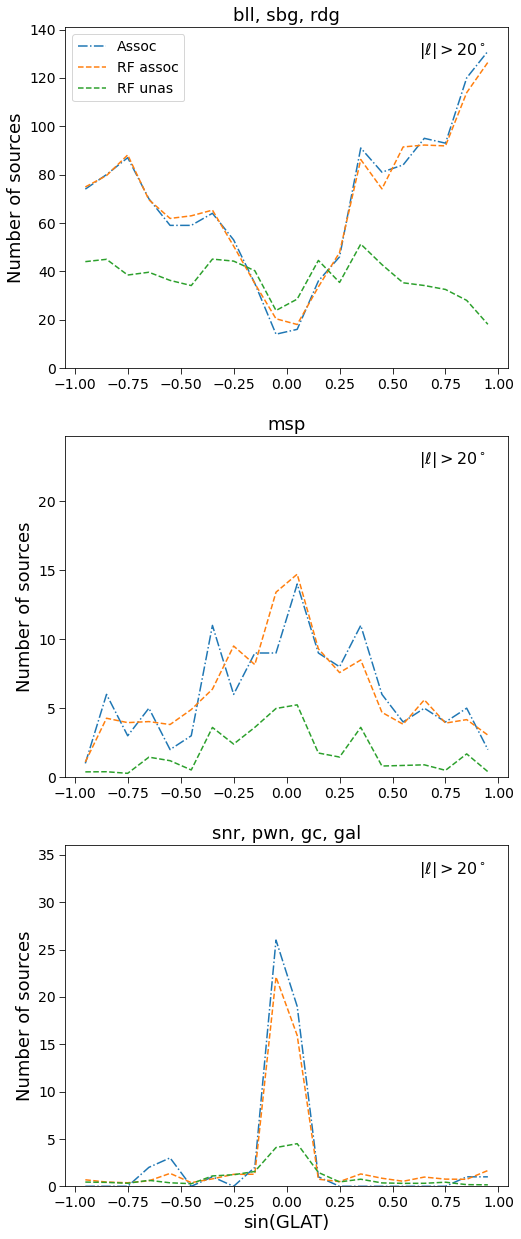

In [1861]:
ymin = 0
pgroup = pgroup1
nrows = len(pgroup)
pyplot.rcParams['figure.figsize'] =  fig_size1

pyplot.figure()
for ind, node in enumerate(pgroup):
    ax = pyplot.subplot(nrows, ncols, ind + 1)
    ymax = 0
    if plot_all_assoc:
        pyplot.plot(binc, hist_all_assoc, ls=':', c=colors[0], label='Assoc')
        pyplot.plot(binc, hist_all_unassoc, ls=':', c=colors[1], label=unas_label)
        ci = 2
    else:
        ci = 0
        
    
    pyplot.plot(binc, assoc_count_hists[node], ls='-.', c=colors[ci], 
                     label='Assoc')

    ymax = np.maximum(ymax, np.max(assoc_count_hists[node]) + 10)
    ci += 1
    
    for alg in algs:
        key = '%s_%s' % (node, alg)
        if purpose == 'DFG':
            ls = ':'
        else:
            ls = lss[alg]
        pyplot.plot(binc, assoc_prob_hists[key], ls=ls, c=colors[ci], 
                         label=alg + ' assoc')
        ymax = np.maximum(ymax, np.max(assoc_prob_hists[key]) + 10)
            
    ci += 1
    for alg in algs:
        key = '%s_%s' % (node, alg)
        if purpose == 'DFG':
            ls = '--'
        else:
            ls = lss[alg]

        pyplot.plot(binc, unas_hists[key], ls=ls, c=colors[ci], 
                         label=alg + ' unas')
        ymax = np.maximum(ymax, np.max(unas_hists[key]) + 10)
    

    if all(fmask == fmask_lon_in):
        text = r'$|\ell| < %i^\circ$' % lmask
    elif all(fmask == fmask_lon_out):
        text = r'$|\ell| > %i^\circ$' % lmask
    else:
        text = ''
    ax.text(0.8, 0.9, text, fontsize=16, horizontalalignment='left', 
                    verticalalignment='bottom', transform=ax.transAxes)

    if purpose == 'DFG':
        for alg in algs:
            ci += 1
            key = '%s_%s' % (node, alg)
            ys = assoc_count_hists[node] + unas_hists[key]
            pyplot.plot(binc, ys, ls='-', c=colors[ci],
                             label='Assoc + %s unas' % alg)
            ymax = np.maximum(ymax, np.max(ys) + 30)
    
            pyplot.plot(binc, np.mean(ys) * np.ones_like(binc), ls='--', c=colors[ci],
                             label='Mean')
    if add_4lac:
        ci += 1
        pyplot.plot(binc, lac_sin_lats_hist, ls=':', c=colors[ci],
                             label='4LAC-DR2')
        

    pyplot.ylim(ymin, ymax)
    if ind == 0:
        if purpose == 'DFG':
            pyplot.legend(loc=(0.64, 0.25), fontsize=14, labelspacing=0.2)
        else:
            pyplot.legend(loc='upper left')

    if ind == len(pgroup) - 1:
        pyplot.xlabel(xlabel)
    pyplot.ylabel('Number of sources')
    cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
    if purpose == 'DFG' and tree_alg == '2class_gal_egal':
        pyplot.title('Extragalactic')
    else:
        pyplot.title(cls_str)
if save_plots and purpose != 'DFG':
    fn = plots_folder + 'lat_profile_group1_%s.pdf' % descr_str
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



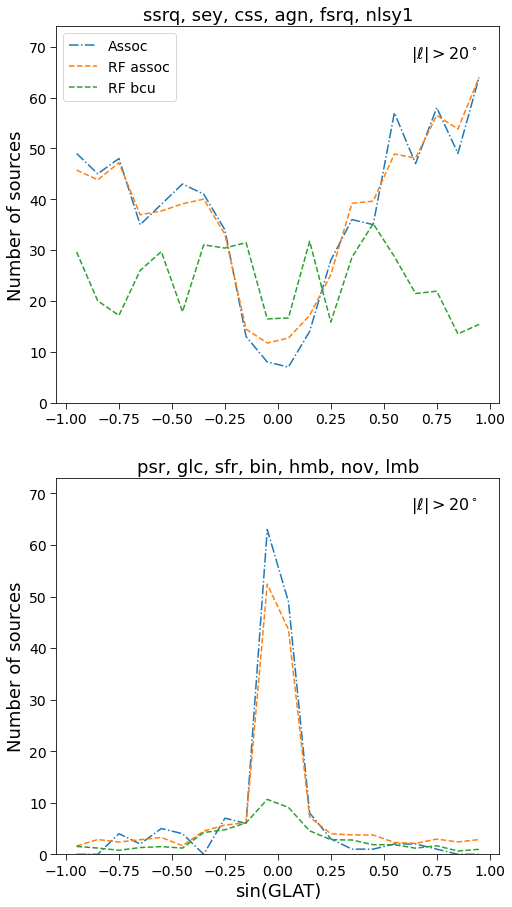

In [1862]:
ymin = 0
pgroup = pgroup2
nrows = len(pgroup)
pyplot.rcParams['figure.figsize'] =  fig_size2


pyplot.figure()
for ind, node in enumerate(pgroup):
    ax = pyplot.subplot(nrows, ncols, ind + 1)
    if node not in assoc_count_hists:
        continue
    ymax = 0
    if plot_all_assoc:
        pyplot.plot(binc, hist_all_assoc, ls=':', c=colors[0], label='Assoc')
        pyplot.plot(binc, hist_all_unassoc, ls=':', c=colors[1], label=unas_label)
        ci = 2
    else:
        ci = 0
        
    
    pyplot.plot(binc, assoc_count_hists[node], ls='-.', c=colors[ci], 
                     label='Assoc')

    ymax = np.maximum(ymax, np.max(assoc_count_hists[node]) + 10)
    ci += 1
    
    for alg in algs:
        key = '%s_%s' % (node, alg)
        if purpose == 'DFG':
            ls = ':'
        else:
            ls = lss[alg]
        pyplot.plot(binc, assoc_prob_hists[key], ls=ls, c=colors[ci], 
                         label=alg + ' assoc')
        ymax = np.maximum(ymax, np.max(assoc_prob_hists[key]) + 10)
            
    for alg in algs:
        ci += 1
        key = '%s_%s' % (node, alg)
        if purpose == 'DFG':
            ls = '--'
        else:
            ls = lss[alg]

        pyplot.plot(binc, unas_hists[key], ls=ls, c=colors[ci], 
                         label='%s %s' % (alg, unas_label))
        ymax = np.maximum(ymax, np.max(unas_hists[key]) + 10)
    

    
    if purpose == 'DFG':
        for alg in algs:
            ci += 1
            key = '%s_%s' % (node, alg)
            ys = assoc_count_hists[node] + unas_hists[key]
            pyplot.plot(binc, ys, ls='-', c=colors[ci], 
                             label='Assoc + %s %s' % (alg, unas_label))
            ymax = np.maximum(ymax, np.max(ys) + 30)
    
    if all(fmask == fmask_lon_in):
        text = r'$|\ell| < %i^\circ$' % lmask
    elif all(fmask == fmask_lon_out):
        text = r'$|\ell| > %i^\circ$' % lmask
    else:
        text = ''
    ax.text(0.8, 0.9, text, fontsize=16, horizontalalignment='left', 
                    verticalalignment='bottom', transform=ax.transAxes)

    
    pyplot.ylim(ymin, ymax)
    if ind == 0:
        if purpose == 'DFG':
            pyplot.legend(loc='upper right', fontsize=14, labelspacing=0.2)
        else:
            pyplot.legend(loc='upper left')
    if ind == len(pgroup) - 1:
        pyplot.xlabel(xlabel)
    pyplot.ylabel('Number of sources')
    cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
    if purpose == 'DFG' and tree_alg == '2class_gal_egal':
        pyplot.title('Galactic')
    else:
        pyplot.title(cls_str)
if save_plots and purpose != 'DFG':
    fn = plots_folder + 'lat_profile_group2_%s.pdf' % descr_str
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



In [1863]:
# lon plot
values = np.rad2deg(np.arccos(xdf['cos(GLON)']))
values *= np.sign(xdf['sin(GLON)'])
#bins = np.linspace(-180, 180, 37)
bins = np.linspace(-180, 180, 19)
binc = (bins[1:] + bins[:-1]) / 2.
xlabel = 'GLON'


In [1864]:
bins

array([-180., -160., -140., -120., -100.,  -80.,  -60.,  -40.,  -20.,
          0.,   20.,   40.,   60.,   80.,  100.,  120.,  140.,  160.,
        180.])

In [1865]:
fmask = fmask_llat
hist_all_assoc = np.histogram(values[assoc_mask & fmask], bins=bins)[0]
hist_all_unassoc = np.histogram(values[unas_mask & fmask], bins=bins)[0]

assoc_count_hists = {}
assoc_prob_hists = {}
unas_hists = {}
for node in nodes:
    assoc_count_hists[node] = np.histogram(values[cls_masks[node] & fmask], bins=bins)[0]
    for alg in algs:
        key = '%s_%s' % (node, alg)
        assoc_prob_hists[key] = np.histogram(values[assoc_mask & fmask], bins=bins, 
                                      weights=cat_df[key][assoc_mask & fmask])[0]
        unas_hists[key] = np.histogram(values[unas_mask & fmask], bins=bins, 
                                      weights=cat_df[key][unas_mask & fmask])[0]



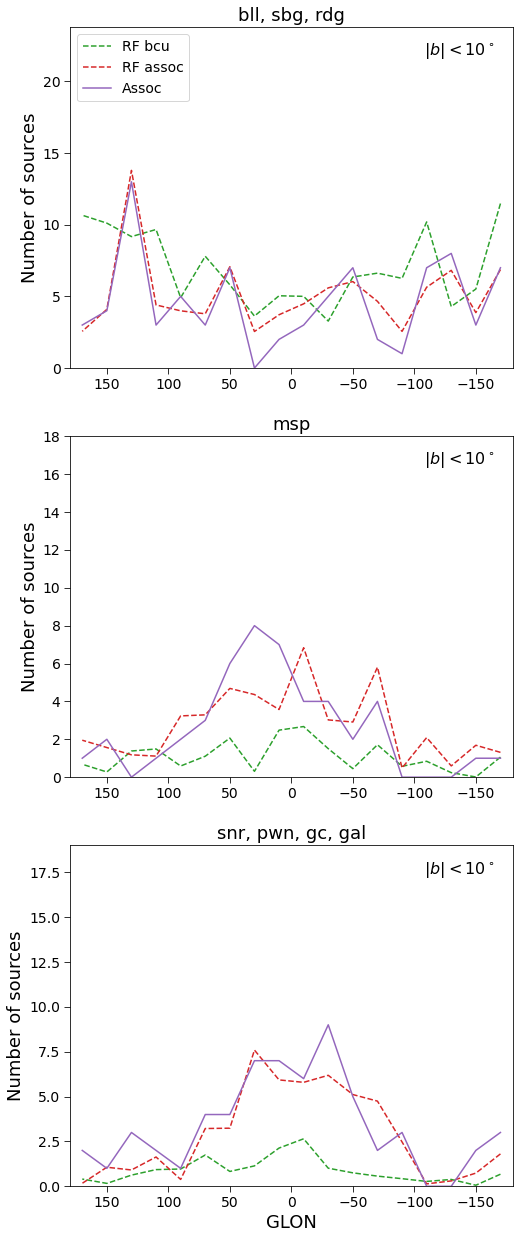

In [1866]:
ymin = 0
pgroup = pgroup1
nrows = len(pgroup)
pyplot.rcParams['figure.figsize'] =  fig_size1


pyplot.figure()
for ind, node in enumerate(pgroup):
    ax = pyplot.subplot(nrows, ncols, ind + 1)
    ymax = 0
    if plot_all_assoc:
        pyplot.plot(binc, hist_all_assoc, ls=':', c=colors[0], label='Assoc')
        pyplot.plot(binc, hist_all_unassoc, ls=':', c=colors[1], label=unas_label)
    ci = 2
    
    for alg in algs:
        key = '%s_%s' % (node, alg)
        pyplot.plot(binc, unas_hists[key], ls=lss[alg], c=colors[ci], 
                         label='%s %s' % (alg, unas_label))
        ymax = np.maximum(ymax, np.max(unas_hists[key]) + 10)
    ci += 1
    
    for alg in algs:
        key = '%s_%s' % (node, alg)
        pyplot.plot(binc, assoc_prob_hists[key], ls=lss[alg], c=colors[ci], 
                         label=alg + ' assoc')
        ymax = np.maximum(ymax, np.max(assoc_prob_hists[key]) + 10)
    ci += 1
    pyplot.plot(binc, assoc_count_hists[node], ls='-', c=colors[ci], 
                     label='Assoc')
    
    if purpose == 'DFG':
        for alg in algs:
            ci += 1
            key = '%s_%s' % (node, alg)
            ys = assoc_count_hists[node] + unas_hists[key]
            pyplot.plot(binc, ys, ls='-', c=colors[ci],
                             label='Assoc + %s %s' % (alg, unas_label))
            ymax = np.maximum(ymax, np.max(ys) + 30)
    
            pyplot.plot(binc, np.mean(ys) * np.ones_like(binc), ls='--', c=colors[ci],
                             label='Mean')
        
    if all(fmask == fmask_llat):
        text = r'$|b| < %i^\circ$' % bmask
    elif all(fmask == fmask_hlat):
        text = r'$|b| > %i^\circ$' % bmask
    else:
        text = ''
    ax.text(0.8, 0.9, text, fontsize=16, horizontalalignment='left', 
                    verticalalignment='bottom', transform=ax.transAxes)

    ymax = np.maximum(ymax, np.max(assoc_count_hists[node]) + 10)
    pyplot.ylim(ymin, ymax)
    pyplot.xlim(180, -180)
    if ind == 0:
        pyplot.legend(loc='upper left')
    if ind == len(pgroup) - 1:
        pyplot.xlabel(xlabel)
    pyplot.ylabel('Number of sources')
    cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
    pyplot.title(cls_str)
if save_plots and purpose != 'DFG':
    fn = plots_folder + 'lon_profile_group1_%s.pdf' % descr_str
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



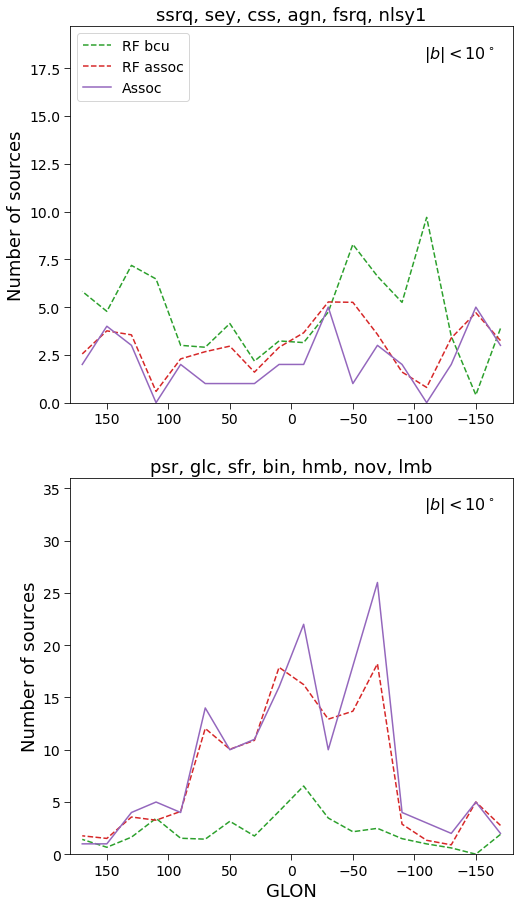

In [1867]:
ymin = 0
pgroup = pgroup2
if purpose == 'DFG' and tree_alg == 'GMM':
    pyplot.rcParams['figure.figsize'] =  fig_size_1plot
else:
    pyplot.rcParams['figure.figsize'] =  fig_size2
    nrows = len(pgroup)


plot_all_unass = False
if not (purpose == 'DFG' and tree_alg == 'GMM'):
    pyplot.figure()
for ind, node in enumerate(pgroup):
    if purpose == 'DFG' and tree_alg == 'GMM':
        pyplot.figure()
        ax = pyplot.subplot(1, 1, 1)
    else:
        ax = pyplot.subplot(nrows, ncols, ind + 1)
    if node not in assoc_count_hists:
        continue

    ymax = 0
    if plot_all_assoc:
        pyplot.plot(binc, hist_all_assoc, ls=':', c=colors[0], label='Assoc')
    if plot_all_unass:
        pyplot.plot(binc, hist_all_unassoc, ls=':', c=colors[1], label=unas_label)
        ymax = np.maximum(ymax, np.max(hist_all_unassoc) + 10)
    ci = 2
    
    for alg in algs:
        key = '%s_%s' % (node, alg)
        if purpose == 'DFG':
            ls = '--' 
        else:
            ls = lss[alg]
        pyplot.plot(binc, unas_hists[key], ls=ls, c=colors[ci], 
                         label='%s %s' % (alg, unas_label))
        ymax = np.maximum(ymax, np.max(unas_hists[key]) + 10)
    ci += 1
    
    for alg in algs:
        key = '%s_%s' % (node, alg)
        if purpose == 'DFG':
            ls = '-.' 
        else:
            ls = lss[alg]
        pyplot.plot(binc, assoc_prob_hists[key], ls=ls, c=colors[ci], 
                         label=alg + ' assoc')
        ymax = np.maximum(ymax, np.max(assoc_prob_hists[key]) + 10)
    ci += 1
    pyplot.plot(binc, assoc_count_hists[node], ls='-', c=colors[ci], 
                     label='Assoc')
    
    if all(fmask == fmask_llat):
        text = r'$|b| < %i^\circ$' % bmask
    elif all(fmask == fmask_hlat):
        text = r'$|b| > %i^\circ$' % bmask
    else:
        text = ''
    ax.text(0.8, 0.9, text, fontsize=16, horizontalalignment='left', 
                    verticalalignment='bottom', transform=ax.transAxes)
    
    ymax = np.maximum(ymax, np.max(assoc_count_hists[node]) + 10)
    pyplot.ylim(ymin, ymax)
    pyplot.xlim(180, -180)
    if ind == 0 or purpose == 'DFG':
        pyplot.legend(loc='upper left')
    if ind == len(pgroup) - 1 or (purpose == 'DFG' and tree_alg == 'GMM'):
        pyplot.xlabel(xlabel)
    pyplot.ylabel('Number of sources')
    cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
    
    
    if purpose == 'DFG':
        pyplot.yscale('log')
        pyplot.ylim(0.5, 3*ymax)
    if purpose == 'DFG' and tree_alg == '2class_gal_egal':
        pyplot.title('Galactic')
    else:
        pyplot.title(cls_str)
    if purpose == 'DFG' and tree_alg == 'GMM' and save_plots:
        fn = plots_folder + 'lon_profile_group2_%i_%s.pdf' % (ind, descr_str)
        print('save figure to file: %s' % (fn))
        pyplot.savefig(fn)

if save_plots and not (purpose == 'DFG' and tree_alg == 'GMM'):
    fn = plots_folder + 'lon_profile_group2_%s.pdf' % descr_str
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



In [1868]:
xdf.columns

Index(['sin(GLAT)', 'cos(GLON)', 'sin(GLON)', 'log10(Energy_Flux100)',
       'log10(Unc_Energy_Flux100)', 'log10(Signif_Avg)', 'LP_index1000MeV',
       'LP_beta', 'LP_SigCurv', 'log10(Variability_Index)', 'CLASS1'],
      dtype='object')

In [1890]:
#pyplot.hist(xdf['LP_SigCurv'], bins=range(30))

In [1870]:
# a variable plot
mask_outliers = False
if 0:
    var_name = 'log10(Energy_Flux100)'
    xlabel = r'log10(Energy_Flux100 [$\rm erg\ cm^{−2} s^{−1}$])'
    xmin, xmax = -12.5, -9.
elif 0:
    var_name = 'LP_index1000MeV'
    xlabel = 'Index at 1 GeV'
    xmin, xmax = 1, 4.
    mask_outliers = True
elif 1:
    var_name = 'PL_Index'
    xlabel = 'PL index'
    xmin, xmax = 1, 4.
    mask_outliers = True
elif 0:
    var_name = 'log10E_cut'
    xlabel = 'log10(E cut)'
    xmin, xmax = 0., 8.
elif 0:
    var_name = 'log10(Pivot_Energy)'
    xlabel = 'log10(Pivot_Energy)'
    xmin, xmax = 0., 8.
elif 0:
    var_name = 'LP_SigCurv'
    xlabel = var_name
    xmin, xmax = 0., 20.
    
ncbins = 20
bins = np.linspace(xmin, xmax, ncbins + 1)
binc = (bins[1:] + bins[:-1]) / 2.
dx = bins[1] - bins[0]

bins_gauss = np.linspace(xmin, xmax, ncbins*10 + 1)
binc_gauss = (bins_gauss[1:] + bins_gauss[:-1]) / 2.

#xmin = bins[0]
#xmax = bins[-1]
density = False

In [1871]:
if var_name in xdf.columns:
    print('take values from xdf')
    values = xdf[var_name]
else:
    # get values from 4FGL-DR3
    from astropy.io import fits
    fn = '../../data_in/gll_psc_v29.fit'
    cat_hdu = fits.open(fn)
    ctab = cat_hdu[1].data 
    cols = [var_name]

    names = np.array([str(x).strip() for x in ctab['Source_Name']], dtype=str)
    df_extra = pd.DataFrame(index=names, columns=cols, data=0.)
    for col in cols:
        if col == 'log10E_cut':
            E0 = ctab['Pivot_Energy']
            d = ctab['PLEC_ExpfactorS']
            b = ctab['PLEC_Exp_Index']
            log10E = np.array(np.log10(E0) + np.log10(b**2 / d) / b)
            df_extra[col] = log10E
        elif col == 'log10(Pivot_Energy)':
            E0 = ctab['Pivot_Energy']
            df_extra[col] = np.array(np.log10(E0))
        else:
            df_extra[col] = np.array(ctab[col], dtype=float)
    values = df_extra[var_name][xdf.index]

In [1872]:
#ctab.dtype.names
np.min(values), np.max(values), bins

(1.0140609741210938,
 3.3713715076446533,
 array([1.  , 1.15, 1.3 , 1.45, 1.6 , 1.75, 1.9 , 2.05, 2.2 , 2.35, 2.5 ,
        2.65, 2.8 , 2.95, 3.1 , 3.25, 3.4 , 3.55, 3.7 , 3.85, 4.  ]))

In [1873]:
fmask = fmask_llat #fmask_llat & fmask_lon_in # fmask_hlat #
hist_all_assoc = np.histogram(values[assoc_mask & fmask], bins=bins, density=density)[0]
hist_all_unassoc = np.histogram(values[unas_mask & fmask], bins=bins, density=density)[0]

mean_dict = {'assoc':{}, 'unas':{}}
std_dict = {'assoc':{}, 'unas':{}}


assoc_count_hists = {}
assoc_prob_hists = {}
unas_hists = {}
for node in nodes:
    assoc_count_hists[node] = np.histogram(values[cls_masks[node] & fmask], bins=bins, density=density)[0]
    if mask_outliers:
        vmask = (values > xmin) & (values < xmax) # outlier mask?
    else:
        vmask = True
    mean_dict['assoc'][node] = np.mean(values[cls_masks[node] & fmask & vmask])
    std_dict['assoc'][node] = np.std(values[cls_masks[node] & fmask & vmask]) / np.sqrt(sum(fmask & vmask))
    for alg in algs:
        key = '%s_%s' % (node, alg)
        assoc_prob_hists[key] = np.histogram(values[assoc_mask & fmask], bins=bins, 
                                      weights=cat_df[key][assoc_mask & fmask], density=density)[0]
        unas_hists[key] = np.histogram(values[unas_mask & fmask], bins=bins, 
                                      weights=cat_df[key][unas_mask & fmask], density=density)[0]
        weights = cat_df[key][unas_mask & fmask & vmask]
        mean_dict['unas'][key] = np.sum(values[unas_mask & fmask & vmask] * weights) / np.sum(weights)
        var = np.sum((values[unas_mask & fmask & vmask] - mean_dict['unas'][key])**2 * weights**2) 
        var /= np.sum(weights)**2
        std_dict['unas'][key] = np.sqrt(var)
        


In [1874]:
dec_tree_cat_dict, mean_dict, std_dict

({1: ['bll', 'sbg', 'rdg'],
  2: ['msp'],
  3: ['snr', 'pwn', 'gc', 'gal'],
  4: ['ssrq', 'sey', 'css', 'agn', 'fsrq', 'nlsy1'],
  5: ['psr', 'glc', 'sfr', 'bin', 'hmb', 'nov', 'lmb']},
 {'assoc': {'1': 2.054710954068655,
   '2': 2.3811748649763023,
   '3': 2.1275047904155295,
   '4': 2.522473396399082,
   '5': 2.4309601059442834},
  'unas': {'1_RF': 2.1408799024544325,
   '2_RF': 2.4833041556482742,
   '3_RF': 2.3319520417170763,
   '4_RF': 2.463857188815262,
   '5_RF': 2.5179559478473346}},
 {'assoc': {'1': 0.0053359959076204585,
   '2': 0.0034638350612291556,
   '3': 0.0074136166787870175,
   '4': 0.0033189695542230357,
   '5': 0.0034436189858537197},
  'unas': {'1_RF': 0.01670587508652814,
   '2_RF': 0.03437513434462349,
   '3_RF': 0.021172738921120766,
   '4_RF': 0.013911004343988865,
   '5_RF': 0.014639411331661287}})

In [1875]:
descr_str

'_nmin60_RF_no_bcu_spp_all_not_assoc_bcu'

In [1876]:
hist_all_assoc

array([  1,   0,   0,   3,   7,  27,  30,  43,  76, 114,  59,  23,   3,
         0,   0,   1,   0,   0,   0,   0])

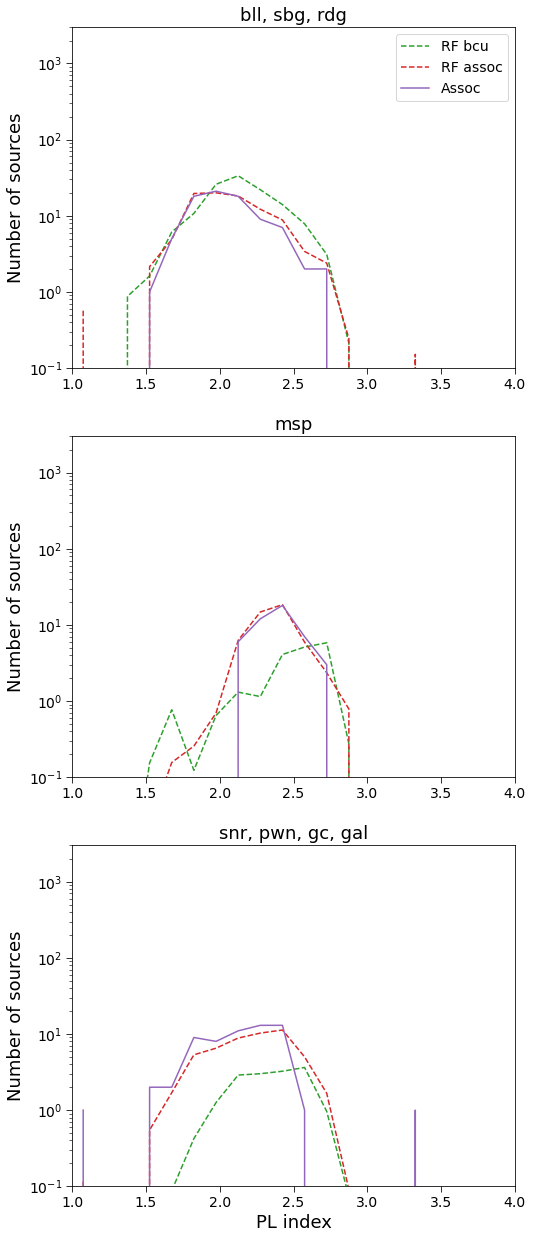

In [1877]:
if density:
    ymin = 0.01
    ymax = 10.
else:
    ymin = 0.1
    ymax = 3.e3
plotfn = pyplot.semilogy
pgroup = pgroup1
nrows = len(pgroup)
pyplot.rcParams['figure.figsize'] =  fig_size1


pyplot.figure()
for ind, node in enumerate(pgroup):
    ax = pyplot.subplot(nrows, ncols, ind + 1)
    if plot_all_assoc:
        plotfn(binc, hist_all_assoc, ls=':', c=colors[0], label='Assoc')
        plotfn(binc, hist_all_unassoc, ls=':', c=colors[1], label=unas_label)
    ci = 2
    
    for alg in algs:
        key = '%s_%s' % (node, alg)
        plotfn(binc, unas_hists[key], ls=lss[alg], c=colors[ci], 
                         label='%s %s' % (alg, unas_label))
    ci += 1
    
    for alg in algs:
        key = '%s_%s' % (node, alg)
        plotfn(binc, assoc_prob_hists[key], ls=lss[alg], c=colors[ci], 
                         label=alg + ' assoc')
    ci += 1
    plotfn(binc, assoc_count_hists[node], ls='-', c=colors[ci], 
                     label='Assoc')
    
    #pyplot.xlim(-12.5, -9)
    pyplot.xlim(xmin, xmax)
    pyplot.ylim(ymin, ymax)
    if ind == 0:
        #pyplot.legend(loc='upper right')
        pyplot.legend(loc='best')
    if ind == len(pgroup) - 1:
        pyplot.xlabel(xlabel)
    pyplot.ylabel('Number of sources')
    cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
    pyplot.title(cls_str)
    #pyplot.grid()
if save_plots and purpose != 'DFG':
    fn = plots_folder + '%s_distr_group1%s.pdf' % (var_name, descr_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



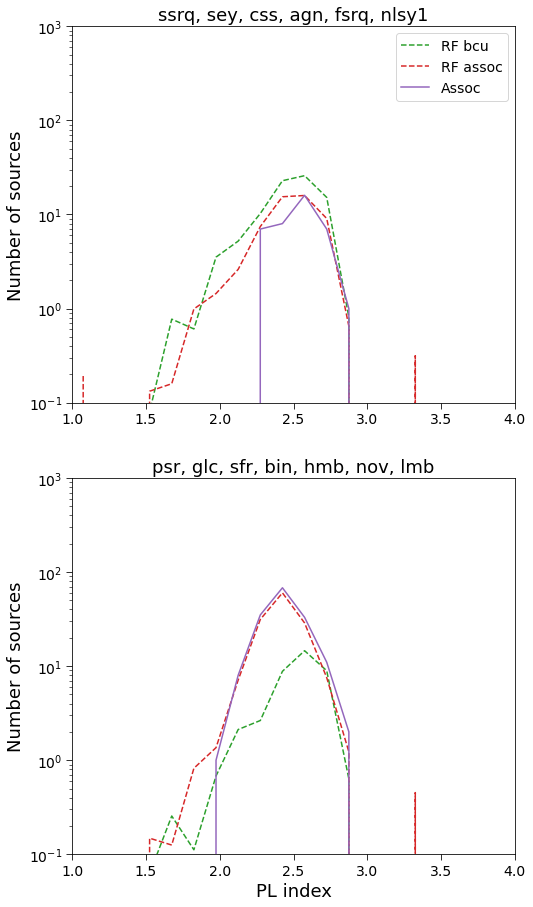

In [1878]:
pgroup = pgroup2
if density:
    ymin = 0.01
    ymax = 10.
else:
    ymin = 0.1
    ymax = 1.e3
plotfn = pyplot.semilogy

nrows = len(pgroup)
pyplot.rcParams['figure.figsize'] =  fig_size2


pyplot.figure()
for ind, node in enumerate(pgroup):
    ax = pyplot.subplot(nrows, ncols, ind + 1)
    if node not in assoc_count_hists:
        continue

    if plot_all_assoc:
        plotfn(binc, hist_all_assoc, ls=':', c=colors[0], label='Assoc')
        plotfn(binc, hist_all_unassoc, ls=':', c=colors[1], label=unas_label)
    ci = 2
    
    for alg in algs:
        key = '%s_%s' % (node, alg)
        plotfn(binc, unas_hists[key], ls=lss[alg], c=colors[ci], 
                         label='%s %s' % (alg, unas_label))
    ci += 1
    
    for alg in algs:
        key = '%s_%s' % (node, alg)
        plotfn(binc, assoc_prob_hists[key], ls=lss[alg], c=colors[ci], 
                         label=alg + ' assoc')
    ci += 1
    plotfn(binc, assoc_count_hists[node], ls='-', c=colors[ci], 
                     label='Assoc')
    
    #pyplot.xlim(-12.5, -9)
    pyplot.xlim(xmin, xmax)
    pyplot.ylim(ymin, ymax)
    if ind == 0:
        #pyplot.legend(loc='upper right')
        pyplot.legend(loc='best')
    if ind == len(pgroup) - 1:
        pyplot.xlabel(xlabel)
    pyplot.ylabel('Number of sources')
    cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
    pyplot.title(cls_str)
if save_plots and purpose != 'DFG':
    fn = plots_folder + '%s_distr_group2%s.pdf' % (var_name, descr_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



In [1879]:
# determine evolution of parameters as a function of latitude
bin_coord = 'sin(GLAT)' #'log10(Energy_Flux100)' # 'log10(Energy_Flux100)'
if bin_coord == 'sin(GLAT)':
    lat_bins = [0, 10, 30, 90]
    vbins = np.sin(np.deg2rad(lat_bins))
elif bin_coord == 'log10(Energy_Flux100)':
    vbins = np.array([-12.5, -11.5, -10.5, -7.5])
elif bin_coord == 'TS':
    df_extra['TS'] = np.sum(ctab['Sqrt_TS_Band']**2, axis=1)
    xdf['TS'] = df_extra['TS'][xdf.index]
    vbins = np.array([10, 100, 500, 1.e6])
    
def vv2label(vv):
    if bin_coord == 'sin(GLAT)':
        return '%i' % np.round(np.rad2deg(np.arcsin(vv)))
    elif bin_coord == 'log10(Energy_Flux100)':
        return '%.1f' % vv
    elif bin_coord == 'TS':
        return '%g' % vv
    
    
nbins = len(vbins) - 1
mean_dict = {}
std_dict = {}
sample_std_dict = {}

hist_all_assoc = {}
hist_all_unassoc = {}
assoc_count_hists = {}
assoc_prob_hists = {}
unas_hists = {}

for i in range(nbins):
    sinb_min = vbins[i]
    sinb_max = vbins[i + 1]
    if bin_coord == 'sin(GLAT)':
        bin_mask = (np.abs(xdf[bin_coord]) > vbins[i]) & (np.abs(xdf[bin_coord]) < vbins[i + 1])
    else: #elif bin_coord == 'log10(Energy_Flux100)':
        bin_mask = (xdf[bin_coord] > vbins[i]) & (xdf[bin_coord] < vbins[i + 1])
    

    fmask = bin_mask #fmask_llat & fmask_lon_in # fmask_hlat #
    hist_all_assoc[i] = np.histogram(values[assoc_mask & fmask], bins=bins, density=density)[0]
    hist_all_unassoc[i] = np.histogram(values[unas_mask & fmask], bins=bins, density=density)[0]

    mean_dict[i] = {'assoc':{}, 'unas':{}}
    std_dict[i] = {'assoc':{}, 'unas':{}}
    
    sample_std_dict[i] = {'assoc':{}, 'unas':{}}

    assoc_count_hists[i] = {}
    assoc_prob_hists[i] = {}
    unas_hists[i] = {}
    for node in nodes:
        assoc_count_hists[i][node] = np.histogram(values[cls_masks[node] & fmask], bins=bins, density=density)[0]
        if mask_outliers:
            vmask = (values > xmin) & (values < xmax) # outlier mask?
        else:
            vmask = True
        mean_dict[i]['assoc'][node] = np.mean(values[cls_masks[node] & fmask & vmask])
        std_dict[i]['assoc'][node] = np.std(values[cls_masks[node] & fmask & vmask]) / np.sqrt(sum(fmask & vmask))
        sample_std_dict[i]['assoc'][node] = std_dict[i]['assoc'][node] * np.sqrt(sum(fmask & vmask))

        for alg in algs:
            key = '%s_%s' % (node, alg)
            assoc_prob_hists[i][key] = np.histogram(values[assoc_mask & fmask], bins=bins, 
                                          weights=cat_df[key][assoc_mask & fmask], density=density)[0]
            unas_hists[i][key] = np.histogram(values[unas_mask & fmask], bins=bins, 
                                          weights=cat_df[key][unas_mask & fmask], density=density)[0]
            weights = cat_df[key][unas_mask & fmask & vmask]
            mean_dict[i]['unas'][key] = np.sum(values[unas_mask & fmask & vmask] * weights) / np.sum(weights)
            var = np.sum((values[unas_mask & fmask & vmask] - mean_dict[i]['unas'][key])**2 * weights**2) 
            var /= np.sum(weights)**2
            std_dict[i]['unas'][key] = np.sqrt(var)
            sample_std_dict[i]['unas'][key] = std_dict[i]['unas'][key] * np.sqrt(np.sum(weights))


In [1880]:
assoc_count_hists

{0: {'1': array([ 0,  0,  0,  1,  5, 18, 21, 18,  9,  7,  2,  2,  0,  0,  0,  0,  0,
          0,  0,  0]),
  '2': array([ 0,  0,  0,  0,  0,  0,  0,  6, 12, 18,  7,  3,  0,  0,  0,  0,  0,
          0,  0,  0]),
  '3': array([ 1,  0,  0,  2,  2,  9,  8, 11, 13, 13,  1,  0,  0,  0,  0,  1,  0,
          0,  0,  0]),
  '4': array([ 0,  0,  0,  0,  0,  0,  0,  0,  7,  8, 16,  7,  1,  0,  0,  0,  0,
          0,  0,  0]),
  '5': array([ 0,  0,  0,  0,  0,  0,  1,  8, 35, 68, 33, 11,  2,  0,  0,  0,  0,
          0,  0,  0])},
 1: {'1': array([  0,   0,   0,   3,  28,  90, 123, 102,  71,  20,   8,   3,   0,
           0,   0,   0,   0,   0,   0,   0]),
  '2': array([ 0,  0,  0,  0,  0,  0,  4, 17, 30, 13,  1,  0,  0,  0,  0,  0,  0,
          0,  0,  0]),
  '3': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]),
  '4': array([ 0,  0,  0,  0,  0,  2,  4, 17, 51, 77, 52, 26, 11,  2,  0,  0,  0,
          0,  0,  0]),
  '5': array([ 0,  0,  0,  0,  0,  0,  1,  5,  7, 12,  3,

In [1881]:
mean_dict

{0: {'assoc': {'1': 2.054710954068655,
   '2': 2.3811748649763023,
   '3': 2.1275047904155295,
   '4': 2.522473396399082,
   '5': 2.4309601059442834},
  'unas': {'1_RF': 2.1408799024544325,
   '2_RF': 2.4833041556482742,
   '3_RF': 2.3319520417170763,
   '4_RF': 2.463857188815262,
   '5_RF': 2.5179559478473346}},
 1: {'assoc': {'1': 2.0395078376999924,
   '2': 2.2434079702083882,
   '3': 2.4807493686676025,
   '4': 2.4506102618107124,
   '5': 2.3679834642717914},
  'unas': {'1_RF': 2.1110434566469345,
   '2_RF': 2.3732879682592936,
   '3_RF': 2.2028326178685287,
   '4_RF': 2.451724638318894,
   '5_RF': 2.4297522602427284}},
 2: {'assoc': {'1': 2.034032252668603,
   '2': 2.195463139902462,
   '3': 2.0046235833849226,
   '4': 2.4723245230588047,
   '5': 2.4248082770241632},
  'unas': {'1_RF': 2.124278147240747,
   '2_RF': 2.2608130242352305,
   '3_RF': 2.084805767970197,
   '4_RF': 2.4639827001026413,
   '5_RF': 2.3978460868549387}}}

In [1882]:
std_dict

{0: {'assoc': {'1': 0.0053359959076204585,
   '2': 0.0034638350612291556,
   '3': 0.0074136166787870175,
   '4': 0.0033189695542230357,
   '5': 0.0034436189858537197},
  'unas': {'1_RF': 0.01670587508652814,
   '2_RF': 0.03437513434462349,
   '3_RF': 0.021172738921120766,
   '4_RF': 0.013911004343988865,
   '5_RF': 0.014639411331661287}},
 1: {'assoc': {'1': 0.004819569650496311,
   '2': 0.002911201946861772,
   '3': 0.0,
   '4': 0.004674341070707878,
   '5': 0.004564956740737876},
  'unas': {'1_RF': 0.011174013921601528,
   '2_RF': 0.02081988927948177,
   '3_RF': 0.02358612641728356,
   '4_RF': 0.010476156544452022,
   '5_RF': 0.015266426928614506}},
 2: {'assoc': {'1': 0.00415149187223734,
   '2': 0.0018756127941045523,
   '3': 0.0029375145574060176,
   '4': 0.003914635161705963,
   '5': 0.0025885893684421215},
  'unas': {'1_RF': 0.010444220328302462,
   '2_RF': 0.025106975778556355,
   '3_RF': 0.034364388949606924,
   '4_RF': 0.010297530734184109,
   '5_RF': 0.021861621112130736}}}

save figure to file: ../../plots/pop_study/RF_nmin60_no_bcu_spp_no_coord_features/lat_profile_PL_Index_node1.pdf
save figure to file: ../../plots/pop_study/RF_nmin60_no_bcu_spp_no_coord_features/lat_profile_PL_Index_node2.pdf
save figure to file: ../../plots/pop_study/RF_nmin60_no_bcu_spp_no_coord_features/lat_profile_PL_Index_node3.pdf
save figure to file: ../../plots/pop_study/RF_nmin60_no_bcu_spp_no_coord_features/lat_profile_PL_Index_node4.pdf
save figure to file: ../../plots/pop_study/RF_nmin60_no_bcu_spp_no_coord_features/lat_profile_PL_Index_node5.pdf


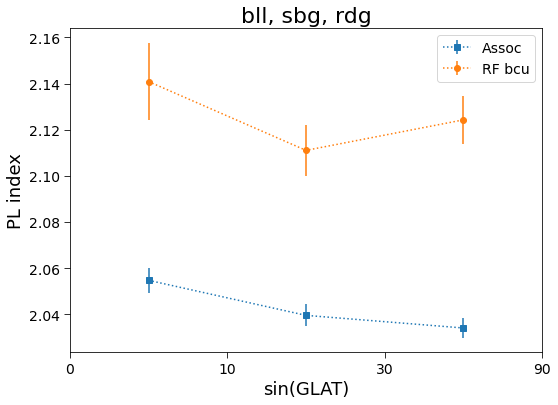

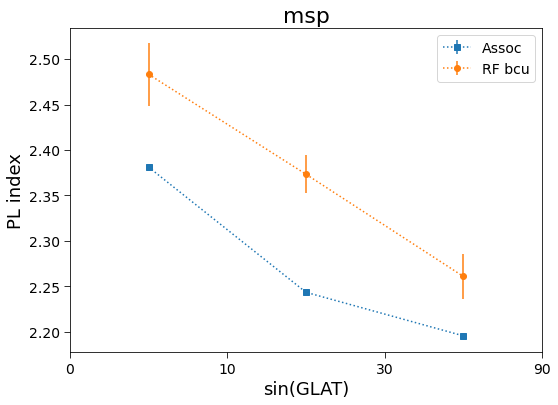

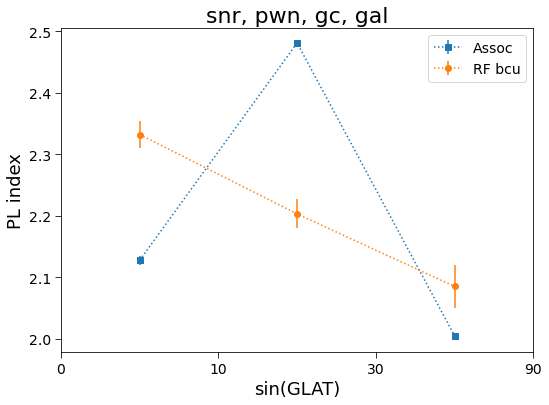

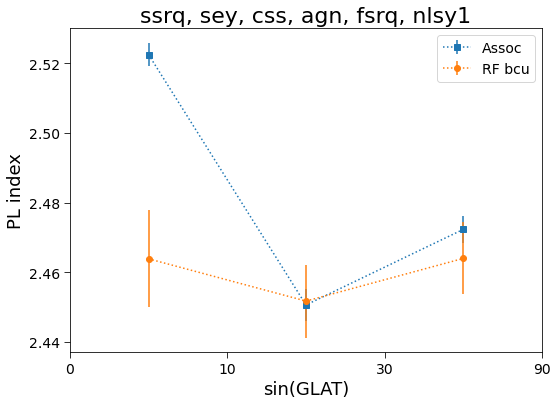

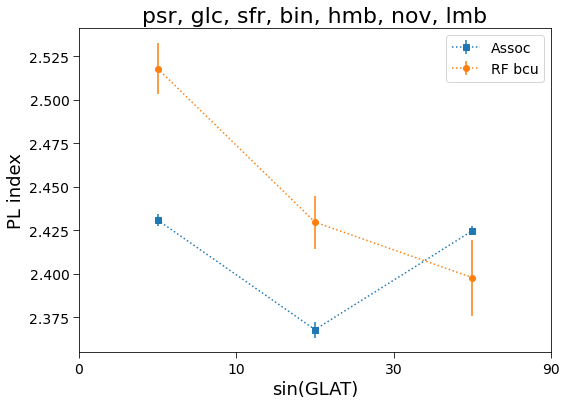

In [1883]:
alg = 'RF'
save_plots = 1
putil.setup_figure_pars()
for node in nodes:
    pyplot.figure()
    xs = np.arange(nbins) + 0.5
    keys = range(nbins)
    y_assoc = [mean_dict[x]['assoc'][node] for x in keys]
    err_assoc = [std_dict[x]['assoc'][node] for x in keys]
    y_unas = [mean_dict[x]['unas']['%s_%s' % (node, alg)] for x in keys]
    err_unas = [std_dict[x]['unas']['%s_%s' % (node, alg)] for x in keys]
    pyplot.errorbar(xs, y_assoc, err_assoc, ls=':', marker='s', label='Assoc')
    pyplot.errorbar(xs, y_unas, err_unas, ls=':', marker='o', label='%s %s' % (alg, unas_label))
    cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
    pyplot.title(cls_str)
    pyplot.legend(loc='best')
    if bin_coord == 'sin(GLAT)':
        pyplot.xticks(ticks=np.arange(len(vbins)), labels=lat_bins)
    elif bin_coord == 'log10(Energy_Flux100)':
        pyplot.xticks(ticks=np.arange(len(vbins)), labels=vbins)
    elif bin_coord == 'TS':
        pyplot.xticks(ticks=np.arange(len(vbins)), labels=vbins)

    
    pyplot.xlabel(bin_coord)
    pyplot.ylabel(xlabel)
    if save_plots:
        fn = plots_folder + 'lat_profile_%s_node%s.pdf' % (var_name, node)
        print('save figure to file: %s' % (fn))
        pyplot.savefig(fn)
        if save_png:
            fn_png = fn.replace('.pdf', '.png')
            pyplot.savefig(fn_png)


In [1884]:
hist_all_assoc[ib]

array([  0,   0,   2,  15,  69, 192, 280, 284, 252, 240, 144,  69,  31,
         8,   0,   0,   0,   0,   0,   0])

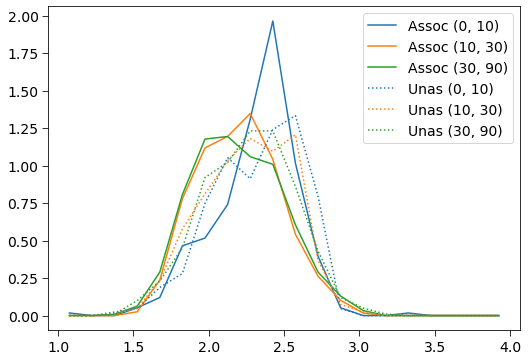

In [1885]:
#plot histograms for different latitude bins
alg = 'RF'

putil.setup_figure_pars(pars_dict=fig_1d_dict)

pyplot.figure()
#ax = pyplot.subplot(1, 2, 1)
plot_density = True

for ib in range(nbins):
    ys = hist_all_assoc[ib]
    if plot_density:
        ys = 1. * ys / (sum(ys) * dx)
    label = 'Assoc (%s, %s)' % (vv2label(vbins[ib]), vv2label(vbins[ib + 1]))
    pyplot.plot(binc, ys, color=colors[ib], label=label)

#ax = pyplot.subplot(1, 2, 2)

for ib in range(nbins):
    ys = hist_all_unassoc[ib]
    if plot_density:
        ys = 1. * ys / (sum(ys) * dx)
    label = 'Unas (%s, %s)' % (vv2label(vbins[ib]), vv2label(vbins[ib + 1]))
    pyplot.plot(binc, ys, ls=':', color=colors[ib], label=label)

#pyplot.title('All unassoc')
pyplot.legend()




/Users/Dmitry/miniconda3/envs/python3/lib/python3.7/site-packages/ipykernel_launcher.py:2: RuntimeWarning: divide by zero encountered in double_scalars
  
/Users/Dmitry/miniconda3/envs/python3/lib/python3.7/site-packages/ipykernel_launcher.py:4: RuntimeWarning: divide by zero encountered in true_divide
  after removing the cwd from sys.path.
/Users/Dmitry/miniconda3/envs/python3/lib/python3.7/site-packages/ipykernel_launcher.py:4: RuntimeWarning: invalid value encountered in multiply
  after removing the cwd from sys.path.


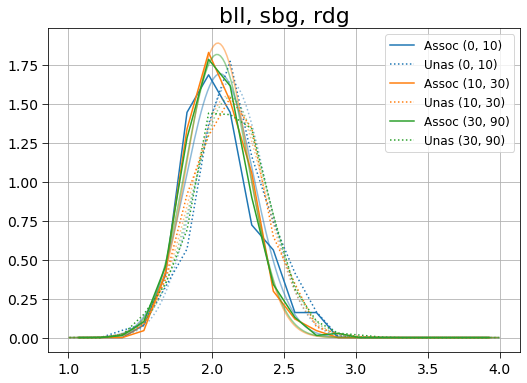

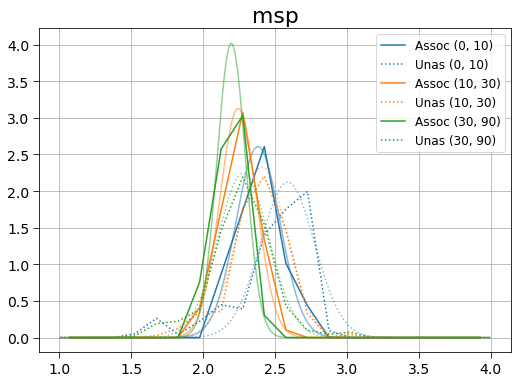

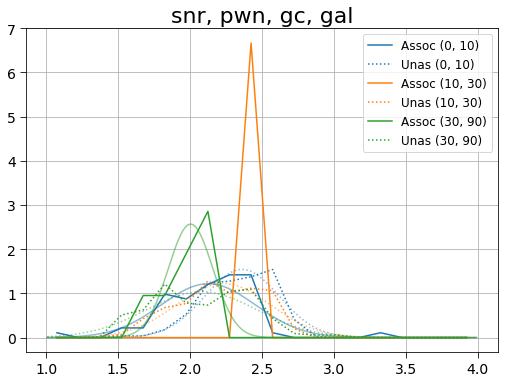

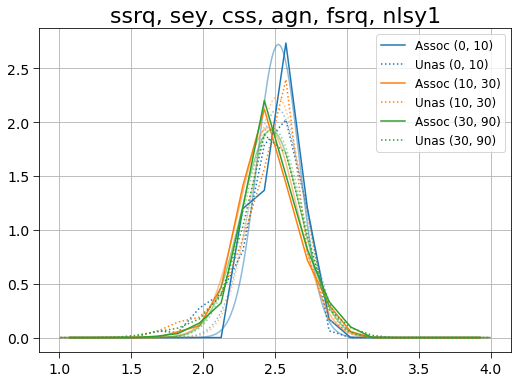

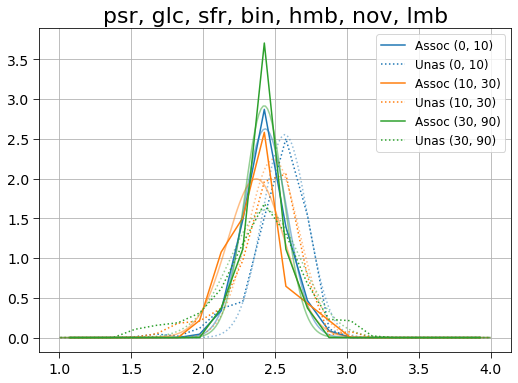

In [1886]:
plot_density = 1
for node in nodes:
    pyplot.figure()
    for ib in range(nbins):
        ys = assoc_count_hists[ib][node]
        if plot_density:
            ys = 1. * ys / (sum(ys) * dx)
        label = 'Assoc (%s, %s)' % (vv2label(vbins[ib]), vv2label(vbins[ib + 1]))
        pyplot.plot(binc, ys, color=colors[ib], label=label)
        
        if plot_density:
            mu = mean_dict[ib]['assoc'][node]
            std = sample_std_dict[ib]['assoc'][node]
            pyplot.plot(binc_gauss, gauss_pdf(mu, std)(binc_gauss), alpha=0.5, c=colors[ib])
            
        ys = unas_hists[ib]['%s_%s' %(node, alg)]
        if plot_density:
            ys = 1. * ys / (sum(ys) * dx)
        label = 'Unas (%s, %s)' % (vv2label(vbins[ib]), vv2label(vbins[ib + 1]))
        pyplot.plot(binc, ys, color=colors[ib], ls=':', label=label)
        
        if plot_density:
            def objf(pars):
                return np.sum((gauss_pdf(pars[0], pars[1])(binc) - ys)**2)
            mu = mean_dict[ib]['unas'][key]
            std = sample_std_dict[ib]['unas'][key]
            pars0 = [mu, std]
            mu, std = minimize(objf, pars0).x
            #print(res)
            pyplot.plot(binc_gauss, gauss_pdf(mu, std)(binc_gauss), ls=':', alpha=0.5, c=colors[ib])

    
    cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
    pyplot.title(cls_str)
    pyplot.legend(fontsize=12)
    pyplot.grid()
    #pyplot.xlim(1, 3.5)


In [1887]:
nsrc_dict = util.get_nsrc_dict(xdf, class_column='CLASS1', classes='associated')

save figure to file: ../../plots/pop_study/RF_nmin60_no_bcu_spp_no_coord_features/extra/assoc_sources_distribution_lat0-10_divide_unas_by7_bcu_PL_Index.pdf


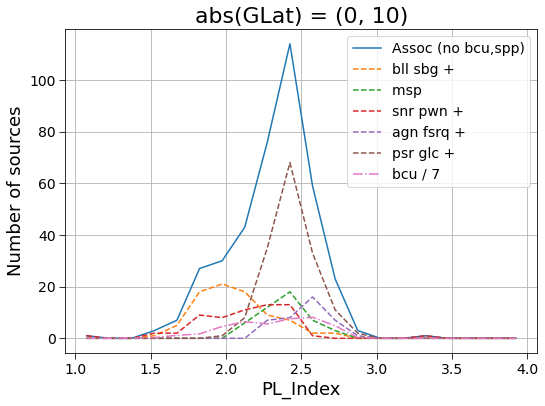

In [1888]:
# plot associated sources classes in a bin
putil.setup_figure_pars(pars_dict=fig_1d_dict)

plot_density = 0
add_unas = 1
divide_unas = 1
ib = 0
pyplot.figure()
ys = hist_all_assoc[ib]
if plot_density:
    ys = 1. * ys / sum(ys)
label = 'Assoc'
if mode == 'no_bcu_spp':
    label += ' (no bcu,spp)'

pyplot.plot(binc, ys, label=label)

for node in nodes:
    ys = assoc_count_hists[ib][node]
    if plot_density:
        ys = 1. * ys / sum(ys)
    #cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
    label = util.list2label(dec_tree_cat_dict[int(node)], nsrc_dict=nsrc_dict, ncl=2, max_only=True)
    pyplot.plot(binc, ys, ls='--', label=label)
    
fr_str = ''
if add_unas:
    ys = hist_all_unassoc[ib]
    if plot_density:
        ys = 1. * ys / sum(ys)
    if ib == 0 and bin_coord == 'sin(GLAT)' and divide_unas:
        factor = 7
        label = '%s / 7' % unas_label
        fr_str = '_divide_unas_by%i' % factor
    else:
        factor = 1
        label = unas_label
        
    
    pyplot.plot(binc, ys / factor, ls='-.', label=label)

pyplot.legend()
pyplot.xlabel(var_name)
if plot_density:
    pyplot.ylabel('Source density')
else:
    pyplot.ylabel('Number of sources')
if bin_coord == 'sin(GLAT)':
    pyplot.title('%s = (%s, %s)' % ('abs(GLat)', vv2label(vbins[ib]), vv2label(vbins[ib + 1])))
else:
    pyplot.title('%s = (%s, %s)' % (bin_coord, vv2label(vbins[ib]), vv2label(vbins[ib + 1])))
    
pyplot.grid()

save_plots = 1
if save_plots:
    if bin_coord == 'sin(GLAT)':
        fn = plots_folder_extra + 'assoc_sources_distribution_lat%s-%s%s_%s_%s.pdf' % \
               (vv2label(vbins[ib]), vv2label(vbins[ib + 1]), fr_str, unas_type, var_name)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png)


save figure to file: ../../plots/pop_study/RF_nmin60_no_bcu_spp_no_coord_features/extra/unas_sources_distribution_lat30-90_bcu_PL_Index.pdf


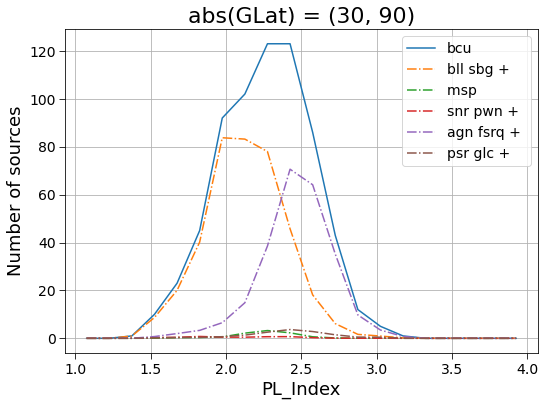

In [1889]:
# plot unassociated sources classes in a bin
plot_density = 0
add_assoc = 1
ib = 2
bins_loc = [ib]
pyplot.figure()
ys = hist_all_unassoc[ib]
if plot_density:
    ys = 1. * ys / sum(ys)
label = unas_label
pyplot.plot(binc, ys, label=label)

for node in nodes:
    for ib in bins_loc:
        ys = unas_hists[ib]['%s_%s' %(node, alg)]
        if plot_density:
            ys = 1. * ys / sum(ys)
        #cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
        label = util.list2label(dec_tree_cat_dict[int(node)], nsrc_dict=nsrc_dict, ncl=2, max_only=True)
        pyplot.plot(binc, ys, ls='-.', c=colors[int(node)], label=label)

assoc_str = ''
if ib == 0 and add_assoc:
    assoc_str = '_add_assoc'
    for node in nodes[-1:]:
        for ib in bins_loc:
            ys = assoc_count_hists[ib][node]
            if plot_density:
                ys = 1. * ys / sum(ys)
            #cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
            cls_str = util.list2label(dec_tree_cat_dict[int(node)], nsrc_dict=nsrc_dict, ncl=2, max_only=True)
            if 0:
                pfactor = 3
                label = 'Assoc %s' % (cls_str)
                pyplot.plot(binc, pfactor * ys, ls='--', c=colors[int(node)], label=label)
            if plot_density or unas_type not in ['unas', 'all_not_assoc']:
                pfactor = 1
                label = 'Assoc %s' % (cls_str)
            elif not plot_density and unas_type == 'all_not_assoc':
                pfactor = 3
                label = 'Assoc %s (x%i)' % (cls_str, pfactor)                
            else:
                pfactor = 2
                label = 'Assoc %s (x%i)' % (cls_str, pfactor)
            pyplot.plot(binc, pfactor * ys, ls='--', c=colors[int(node)], label=label)
        
pyplot.legend()
pyplot.xlabel(var_name)
if plot_density:
    pyplot.ylabel('Source density')
else:
    pyplot.ylabel('Number of sources')
if bin_coord == 'sin(GLAT)':
    pyplot.title('%s = (%s, %s)' % ('abs(GLat)', vv2label(vbins[ib]), vv2label(vbins[ib + 1])))
else:
    pyplot.title('%s = (%s, %s)' % (bin_coord, vv2label(vbins[ib]), vv2label(vbins[ib + 1])))
    
pyplot.grid()

save_plots = 1
if save_plots:
    if bin_coord == 'sin(GLAT)':
        fn = plots_folder_extra + 'unas_sources_distribution_lat%s-%s_%s_%s%s.pdf' % \
               (vv2label(vbins[ib]), vv2label(vbins[ib + 1]), unas_type, var_name, assoc_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png)

